# Task 4 – Datengrundlage

**Ziel:** Beschreibung aller Eingangsdaten für Task 4: BDEW-Standardlastprofile (Haushalt, Gewerbe, Landwirtschaft), Windenergieanlage, PV-Modul, Wetterdaten, die Erzeugungsanlagen der Szenarien (Windpark, PV-Freiflächenanlage) und die Haushalte mit PV-Anlage und Batteriespeicher im Ortsnetz. Am Ende steht das **zentrale Quellenverzeichnis**, auf das sich alle Notebooks von Task 4 beziehen.

**Aufbau des Notebooks:**

1. Daten laden: Lastprofile, Windenergieanlage, PV-Anlage, Wetterdaten, Erzeugungsanlagen, Haushalte mit PV und Speicher
2. Netzdaten (Verweis auf Teil 1 und Teil 2)
3. Quellenverzeichnis

## Importe

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

TASK4 = Path("..")                     # Ordner task4
import profiles as pr
import weather as wt
from profiles import Lastprofil, Month, DayType, Season

import plots as plots

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 20 unterscheidbare Farben, damit alle 15 Busse in einem Diagramm unterscheidbar bleiben
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

Module im Ordner `task4` (Beschreibung siehe `README.md`):

- `profiles.py`: Einlesen und Aufbereiten der BDEW-Standardlastprofile 2025 (Wochen bilden, Dynamisierung, Skalierung), übernommen aus Task 2 und erweitert
- `weather.py`: Wetterdaten (Open-Meteo) und Umrechnung in PV- und Windleistung über die Kennlinien, übernommen aus Task 2
- `plots.py`: Diagramme mit einheitlicher Zeitachse (Uhrzeit im 6-Stunden-Takt, Tageswechsel als senkrechte Linie, Datum über jedem Tag) Komponentenübersicht des Netzes und `table()` für formatierte Tabellen (farbig, wenn `jinja2` installiert ist)
- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für die saisonale Lastflussrechnung (Abschnitt 3.2)

## 1 Daten laden

Alle Eingangsdaten werden einmal zu Beginn geladen und stehen danach in Variablen zur Verfügung:

| Variable | Datei | Inhalt |
|---|---|---|
| `PROFILES` | `data/BDEW_H25_Haushalte.csv`, `data/BDEW_G25_Gewerbe.csv`, `data/BDEW_L25_Landwirtschaft.csv` | BDEW-Standardlastprofile 2025: H25 (Haushalt), G25 (Gewerbe), L25 (Landwirtschaft), je 12 Monate × 3 Tagtypen × 96 Viertelstunden |
| `WEATHER` | `data/weather_weeks_2025.csv` | je Monat eine typische Woche (stündlich) mit Wetter und berechneter PV- und Windleistung |

Die Wetterdaten wurden in Task 2 einmalig über die Open-Meteo-API abgerufen und als CSV gespeichert; das Notebook benötigt deshalb keinen Internetzugang.

In [2]:
DATA = TASK4 / "data"
WEATHER_FILE = DATA / "weather_weeks_2025.csv"

PROFILES = pr.load_profiles(DATA)
WEATHER = wt.load_weather_weeks(WEATHER_FILE)                  # {Month: DataFrame mit 168 Stunden}
WEEK_STARTS = {m: df.index[0] for m, df in WEATHER.items()}     # Montag jeder Wetterwoche


for profil, df in PROFILES.items():
    print(f"{profil.label}: {df.shape[0]} Viertelstunden × {df.shape[1]} Spalten (Monat, Tagtyp)")
print(f"Wetter:     {len(WEATHER)} Wochen × {len(next(iter(WEATHER.values())))} Stunden")

H25 – Haushalt: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
G25 – Gewerbe allgemein: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
L25 – Landwirtschaft: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
Wetter:     12 Wochen × 168 Stunden


### 1.1 Lastprofile (BDEW H25, G25, L25)

#### Haushalte (H25)

**Herkunft:** Das Standardlastprofil H25 ist der Nachfolger des Haushaltsprofils H0 aus dem Jahr 1999. Es wurde im Auftrag des BDEW von der BTU EVU Beratung GmbH aus Abrechnungsdaten von 62 Verteilnetzbetreibern der Jahre 2018 und 2019 erstellt [1, S. 3]. Weil zu dieser Zeit bereits PV-Anlagen in Betrieb waren, enthält das Profil einen moderaten PV-Eigenverbrauch [1, S. 3]. Die Daten stammen aus der BDEW-Veröffentlichung der repräsentativen Profile 2025 [2].

**Aufbau der Datei:** 12 Monate × 3 Tagtypen (WT = Werktag, SA = Samstag, FT = Sonn- und Feiertag) mit je 96 Viertelstundenwerten. Die Werte sind Energiemengen in kWh je Viertelstunde, normiert auf einen Jahresverbrauch von 1 Mio. kWh [1, S. 3].

**Aufbereitung:**

1. *Woche bilden:* Montag bis Freitag erhalten den Tagtyp WT, Samstag SA, Sonntag FT. Wochen mit gesetzlichem Feiertag (NRW) werden bei der Auswahl der Wochen ausgeschlossen, damit die Annahme „fünf Werktage“ gilt.
2. *Leistung:* Die Energie einer Viertelstunde wird in die mittlere Leistung umgerechnet: P = E / 0,25 h = 4 · E.
3. *Dynamisierung:* H25 ist „entdynamisiert“; beim Ausrollen ist die Dynamisierungsfunktion anzuwenden [1, S. 3–4]. Sie bildet den Jahresgang des Verbrauchs ab (im Winter höher, im Sommer niedriger):

   F(t) = −3,92·10⁻¹⁰·t⁴ + 3,2·10⁻⁷·t³ − 7,02·10⁻⁵·t² + 2,1·10⁻³·t + 1,24 &nbsp;&nbsp; (t = Tag des Jahres) [3]

   Der Faktor wird auf vier Nachkommastellen gerundet [1, S. 4] und liegt zwischen etwa 0,79 (Juli/August) und 1,26 (Ende Dezember).
4. *Skalierung:* P_Haushalt = P_norm · F(t) · W_a / 1 000 000 kWh mit dem Jahresverbrauch W_a des Haushalts.
5. *Stundenwerte:* Mittelwert der vier Viertelstundenleistungen einer Stunde.

**Vorzeichen und Einheiten:** Die Last wird im Verbraucherzählpfeilsystem angegeben (Bezug positiv), in pandapower in MW (`unit="MW"`). Die Blindleistung ist im Profil nicht enthalten und wird bei der Einbindung ins Netz über einen Leistungsfaktor festgelegt.

#### Gewerbe (G25)

**Herkunft:** G25 („Gewerbe allgemein“) ist das Standardlastprofil für Gewerbekunden aus derselben BDEW-Veröffentlichung 2025 wie H25 [2]. Es ersetzt das frühere Profil G0 und beschreibt einen durchschnittlichen Gewerbebetrieb ohne ausgeprägte Branchencharakteristik.

**Aufbau:** wie H25 – 12 Monate × 3 Tagtypen (WT, SA, FT) mit je 96 Viertelstundenwerten in kWh, normiert auf 1 Mio. kWh Jahresverbrauch.

**Unterschied zu H25:** Für G25 ist die Dynamisierungsfunktion **nicht** anzuwenden (Hinweis im Dateikopf und [1]). Die Aufbereitung beschränkt sich daher auf Wochenbildung, Umrechnung in Leistung (P = 4 · E), Skalierung auf den Jahresverbrauch und Mittelung auf Stundenwerte.

**Verwendung:** Im CIGRE-Netz gibt es Wohngebietslasten (R, *residential*) und Gewerbe-/Industrielasten (CI, *commercial/industrial*). Für die zeitliche Variation der R-Lasten wird H25, für die CI-Lasten G25 verwendet.

#### Landwirtschaft (L25)

**Herkunft:** L25 ist das Standardlastprofil für landwirtschaftliche Betriebe aus der BDEW-Veröffentlichung 2025 [1], [2]. Weil keine spezifischen Messzeitreihen vorlagen, beruht es auf dem bisherigen VDEW-Profil L0 und wurde auf die neue Form mit 12 Monaten gebracht. Es wird ein einziges Profil für alle Landwirtschaftsbetriebe bereitgestellt [1, S. 4].

**Aufbau und Aufbereitung:** wie G25 – 12 Monate × 3 Tagtypen mit je 96 Viertelstundenwerten, normiert auf 1 Mio. kWh Jahresverbrauch [1, S. 3]. L25 enthält **keine** Dynamisierung [1, S. 4]; die Aufbereitung entspricht daher G25.

**Hinweis zur Datei:** Die CSV-Datei enthält am Zeilenende leere Spalten; beim Einlesen werden nur die Spalten der zwölf Monate und drei Tagtypen übernommen.

**Verwendung:** In den CIGRE-Netzen gibt es keine Landwirtschaftslasten. Das Profil steht in der Simulationssoftware als `Profile.LANDWIRTSCHAFT` zur Verfügung, wird in Task 4 aber nicht verwendet.

**Darstellung:** Für jeden Monat werden die Profile für eine Woche in Stundenwerten gezeigt, alle bezogen auf denselben Jahresverbrauch von 1 Mio. kWh (H25 dynamisiert, G25 und L25 ohne Dynamisierung). Die Woche liegt auf denselben Kalendertagen wie die typische Wetterwoche des Monats (Abschnitt 1.4), sodass Last und Erzeugung später direkt kombiniert werden können.

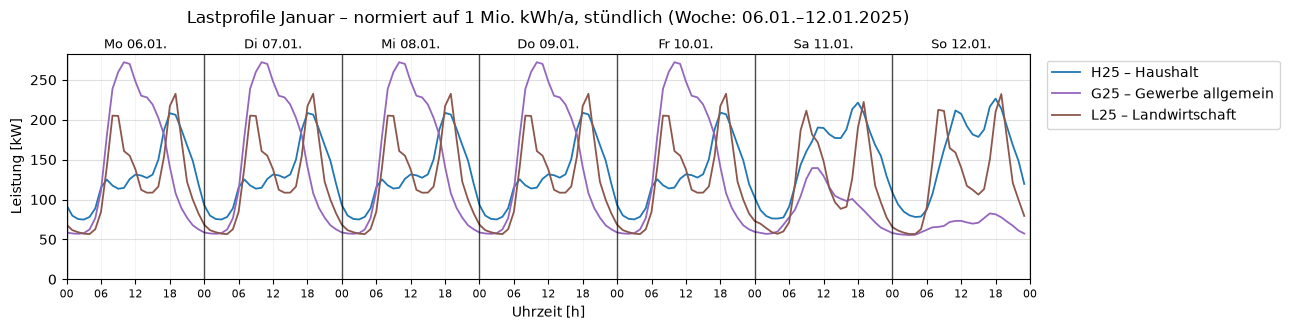

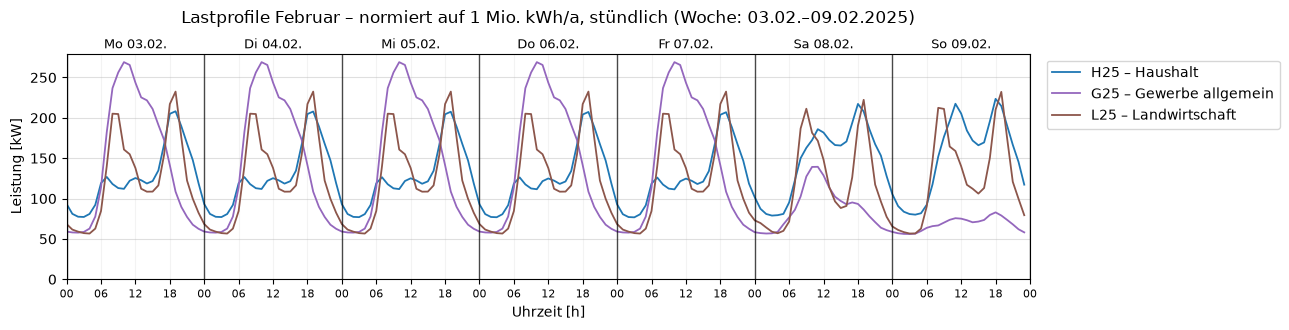

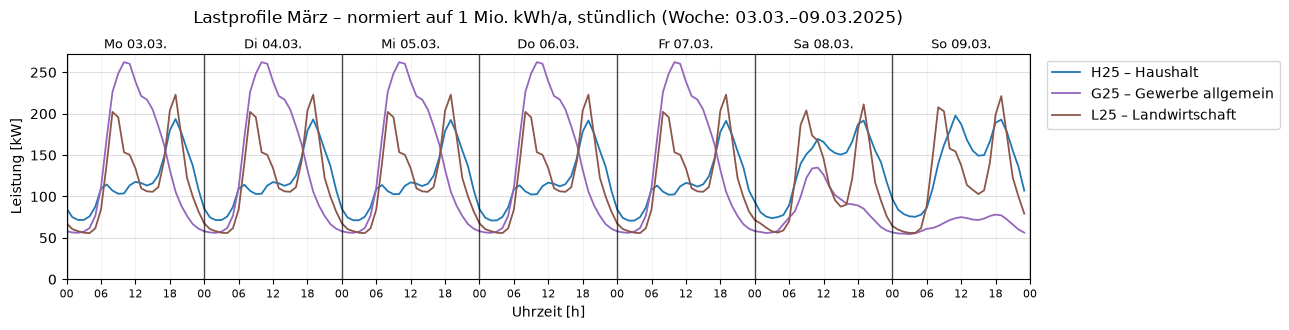

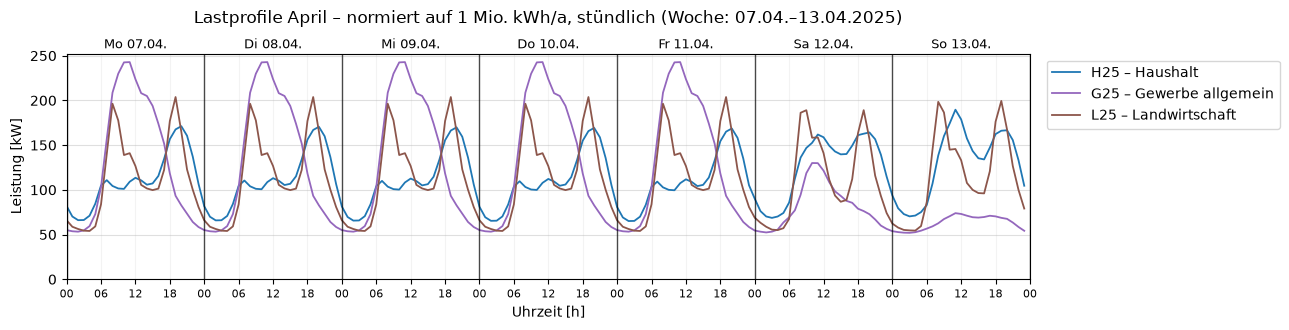

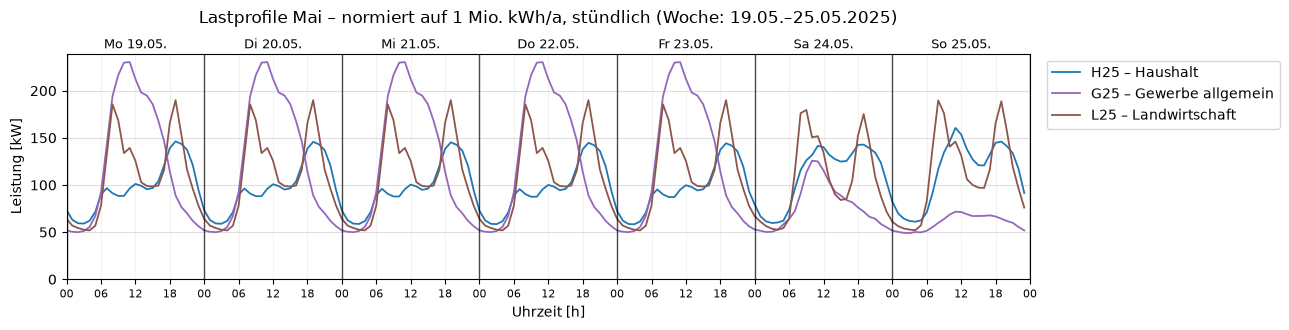

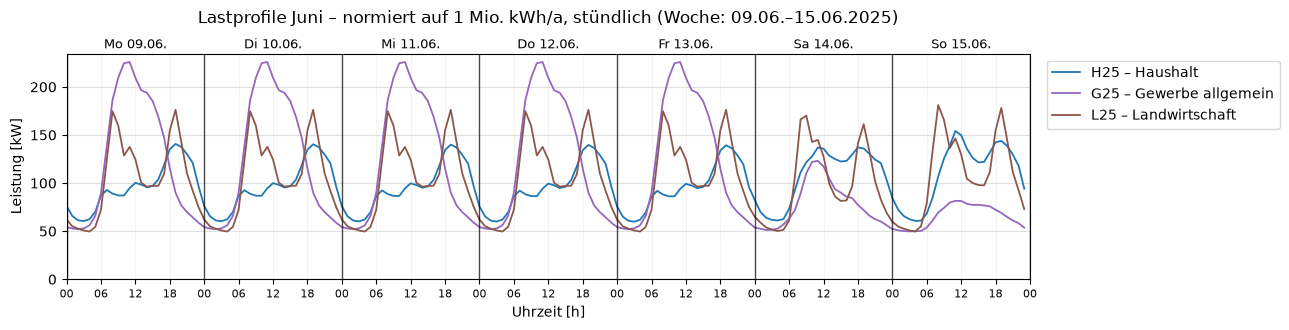

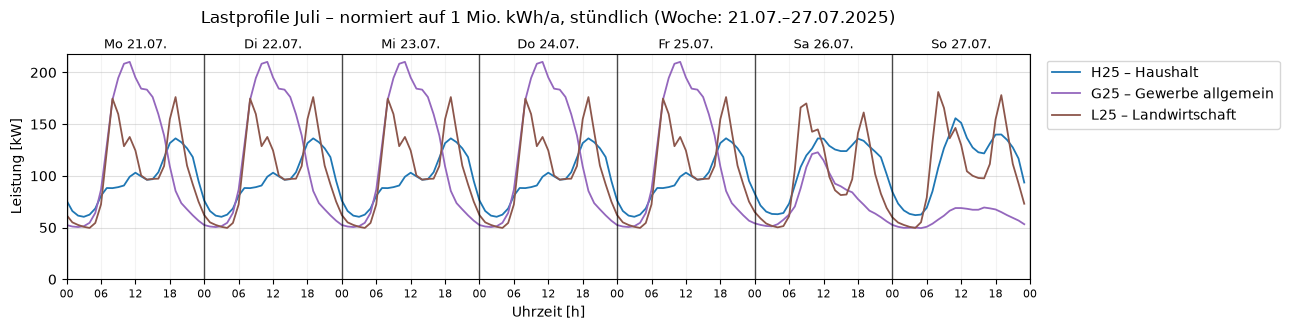

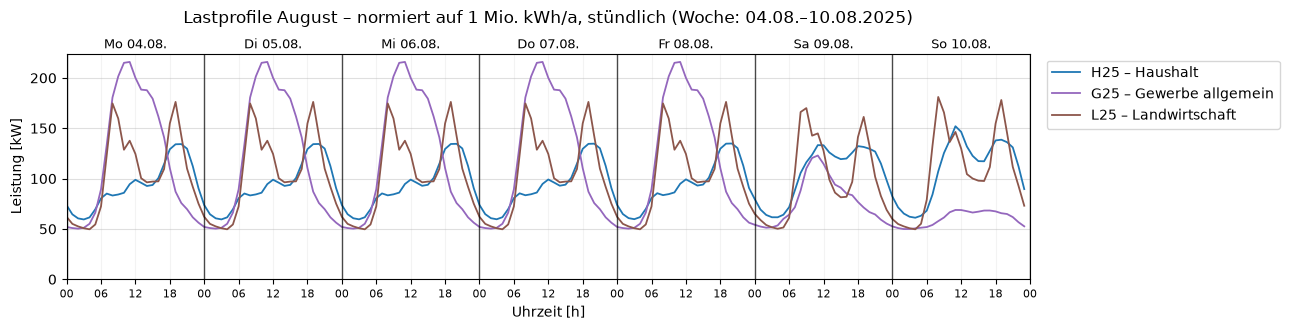

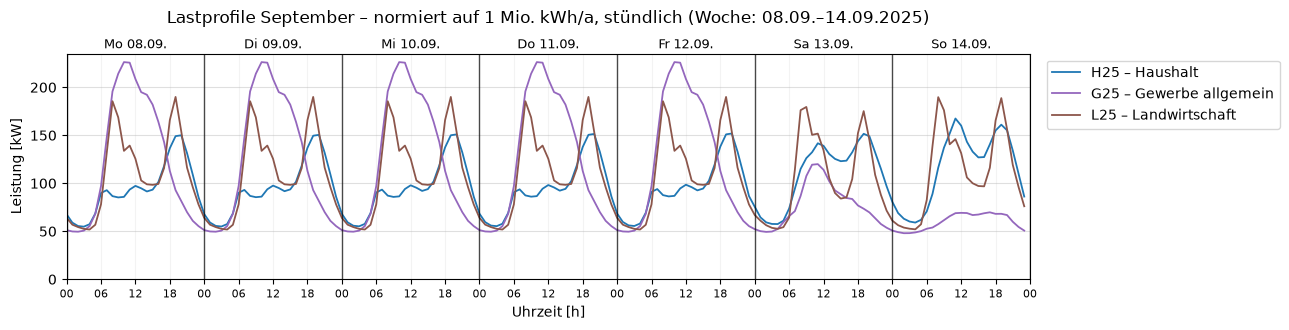

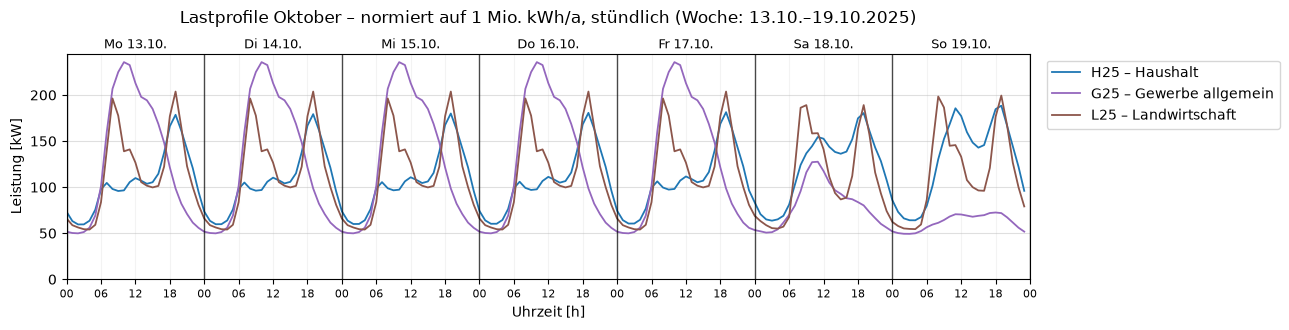

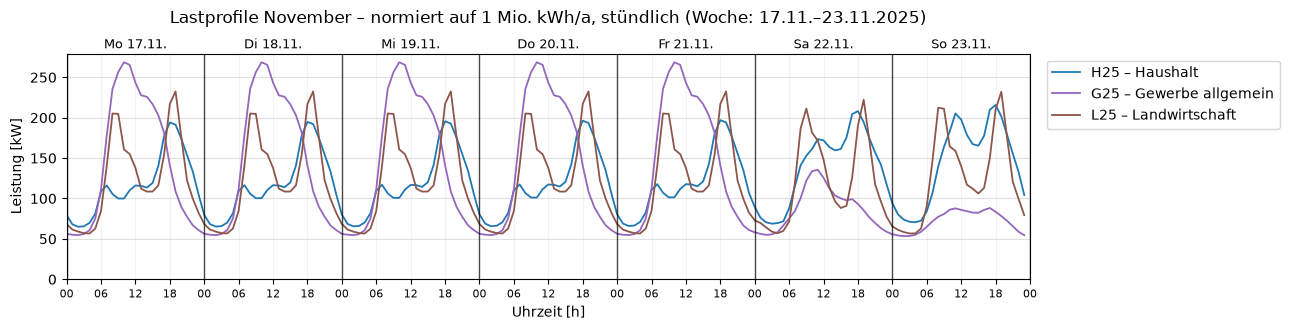

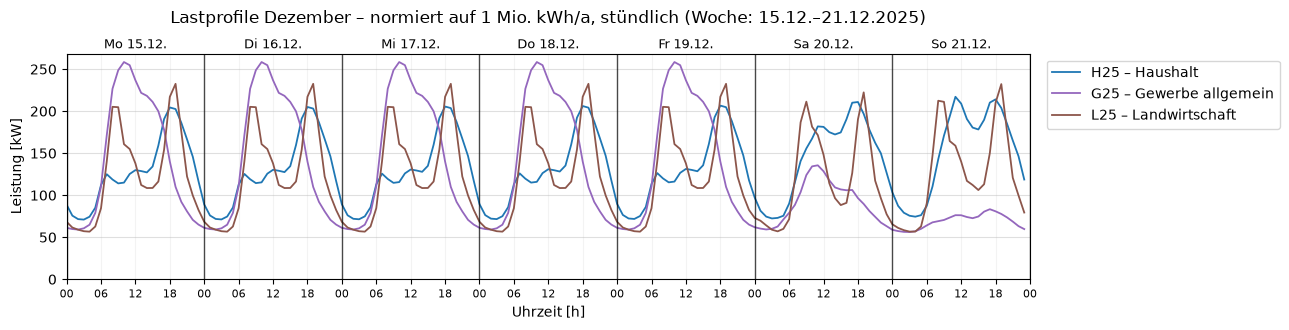

In [3]:
LOAD_PROFILES = [Lastprofil.HAUSHALT, Lastprofil.GEWERBE, Lastprofil.LANDWIRTSCHAFT]

for month in Month:
    weeks = {p.label: pr.build_week(PROFILES, p, month, annual_kwh=pr.NORM_KWH, unit="kW",
                                    start=WEEK_STARTS[month], resolution="1h")
             for p in LOAD_PROFILES}
    first = next(iter(weeks.values()))
    plots.plot_load_week(weeks, f"Lastprofile {month.label} – normiert auf 1 Mio. kWh/a, stündlich "
                                f"(Woche: {first.index[0]:%d.%m.}–{first.index[-1]:%d.%m.%Y})")
    plt.show()

**Wochenenergie je Monat** (alle Profile normiert auf 1 Mio. kWh/a; ein Jahr hat 52,1 Wochen, im Mittel also etwa 19 200 kWh je Woche):

In [4]:
ALLE = [Lastprofil.HAUSHALT, Lastprofil.GEWERBE, Lastprofil.LANDWIRTSCHAFT]
energy = pd.DataFrame({
    p.label: [pr.build_week(PROFILES, p, m, start=WEEK_STARTS[m], resolution="1h").sum() for m in Month]
    for p in ALLE
}, index=[m.label for m in Month])
energy["G25/H25"] = energy.iloc[:, 1] / energy.iloc[:, 0]
energy["L25/H25"] = energy.iloc[:, 2] / energy.iloc[:, 0]
energy.round(2)

,H25 – Haushalt,G25 – Gewerbe allgemein,L25 – Landwirtschaft,G25/H25,L25/H25
Januar,22719.75,21518.05,20782.75,0.95,0.91
Februar,22299.51,21289.32,20782.75,0.95,0.93
März,20474.20,20684.52,20215.44,1.01,0.99
April,19315.88,19364.30,19080.82,1.00,0.99
Mai,16945.86,18328.34,18253.72,1.08,1.08
Juni,16707.49,18356.55,17426.28,1.10,1.04
Juli,16655.36,17388.90,17426.28,1.04,1.05
August,16270.44,17708.41,17426.28,1.09,1.07
September,16721.62,18225.32,18253.72,1.09,1.09
Oktober,18761.87,18857.81,19080.82,1.01,1.02


**Vergleich der Profile:**

- **H25 (Haushalt):** Morgen- und ausgeprägte Abendspitze (ca. 18–20 Uhr), am Wochenende höherer Verbrauch über den Tag. Durch die Dynamisierung ist der Verbrauch im Winter deutlich höher als im Sommer.
- **G25 (Gewerbe):** hohe Leistung an Werktagen während der Betriebszeiten (etwa 7–17 Uhr, Maximum vormittags), deutlich niedrigere Leistung nachts, samstags und vor allem sonntags. Der Jahresgang ist schwächer, weil keine Dynamisierung angewendet wird.
- **L25 (Landwirtschaft):** Tagesgang mit Morgenspitze gegen 8–9 Uhr und Abendspitze gegen 19 Uhr, kaum Unterschied zwischen Werktag, Samstag und Sonntag; der Jahresgang ist ähnlich schwach wie bei G25 (Wochenenergie 0,91 bis 1,09 × H25).
- Die Lastspitzen fallen zeitlich auseinander: Gewerbe tagsüber, Haushalte abends. Gewerbelasten fallen damit zeitlich besser mit der PV-Erzeugung zusammen als Haushaltslasten.

**Skalierung über die Jahreshöchstleistung:** In der Simulationssoftware wird jede Last über ihre höchste Stundenleistung im Jahr skaliert (Task 3). Die Tabelle zeigt die Jahreshöchstleistung je 1 Mio. kWh und den Jahresverbrauch, der sich bei gleicher Höchstleistung ergibt (bezogen auf H25).

In [5]:
import timeseries as tsm
from elements import Profile

spitzen = pd.DataFrame({"Jahreshöchstleistung [kW je 1 Mio. kWh]": {
    p.value: tsm.annual_peak_mw_per_kwh(p) * 1e9 for p in
    [Profile.HAUSHALT, Profile.GEWERBE, Profile.LANDWIRTSCHAFT]}})
spitzen["Jahresverbrauch bei gleicher Höchstleistung (H25 = 1)"] = (
    spitzen.iloc[0, 0] / spitzen.iloc[:, 0])
spitzen.round(2)

,Jahreshöchstleistung [kW je 1 Mio. kWh],Jahresverbrauch bei gleicher Höchstleistung (H25 = 1)
Haushalt (BDEW H25),226.64,1.00
Gewerbe (BDEW G25),272.12,0.83
Landwirtschaft (BDEW L25),232.52,0.97


### 1.2 Windenergieanlage (Vestas V90-2.0 MW)

**Anlagendaten** [7]: Nennleistung 2,0 MW, Rotordurchmesser 90 m (überstrichene Fläche A ≈ 6 362 m²), Nabenhöhen 80 / 95 / 105 m, Einschaltgeschwindigkeit 4 m/s, Nenngeschwindigkeit 13 m/s, Abschaltgeschwindigkeit 25 m/s. Verwendet wird eine Nabenhöhe von 105 m.

**Physikalischer Hintergrund:** Die im Wind enthaltene Leistung, die durch die Rotorfläche strömt, ist

P_Wind = ½ · ρ · A · v³

mit der Luftdichte ρ ≈ 1,225 kg/m³. Eine Windenergieanlage kann davon nur den Anteil c_p (Leistungsbeiwert) entnehmen; theoretisch höchstens c_p,Betz = 16/27 ≈ 0,59 [9]. Real erreichte Werte und die Regelung der Anlage sind in der **Leistungskennlinie** P(v) zusammengefasst, die der Hersteller für eine Standard-Luftdichte angibt. Sie hat vier Bereiche [9]:

| Bereich | Windgeschwindigkeit | Leistung |
|---|---|---|
| Stillstand | v < v_ein | 0 |
| Teillast | v_ein ≤ v < v_Nenn | steigt etwa mit v³ |
| Volllast | v_Nenn ≤ v < v_ab | Nennleistung (Pitch-Regelung begrenzt die Leistung) |
| Sturmabschaltung | v ≥ v_ab = 25 m/s | 0 |

**Kennlinie:** Die Stützstellen (Schrittweite 0,5 m/s) stammen aus der Turbinendatenbank der Open Energy Database (OEDB), die mit der Python-Bibliothek *windpowerlib* ausgeliefert wird; als Quelle ist dort die oben genannte Herstellerangabe auf wind-turbine-models.com eingetragen [8]. Zwischen den Stützstellen wird linear interpoliert. Die Tabelle beginnt bereits bei 3,5 m/s mit 42 kW, während [7] eine Einschaltgeschwindigkeit von 4 m/s nennt. Oberhalb von 12,5 m/s wird die Nennleistung von 2 000 kW angesetzt.

**Höhenumrechnung:** Die Windgeschwindigkeit nimmt mit der Höhe zu. Die API liefert sie in 100 m Höhe; auf die Nabenhöhe h wird mit dem Potenzgesetz umgerechnet [9]:

v_Nabe = v_100 · (h / 100 m)^α, &nbsp; α = 1/7

Bei h = 105 m ergibt sich ein Faktor von 1,007. Der Einfluss ist also gering.

**Vereinfachungen:** keine Korrektur der Luftdichte (Temperatur, Höhe), keine Verfügbarkeitsverluste, keine Abschattung durch andere Anlagen, Stundenwerte statt Böen.

**Normierung:** Neben der Leistung in kW wird die Leistung bezogen auf die Nennleistung gespeichert (`wind_pu`). Damit lässt sich die Zeitreihe auch auf andere Anlagengrößen übertragen. Bei der Einbindung ins Netz kann die Zeitreihe so auf die jeweilige Anlagengröße skaliert werden.

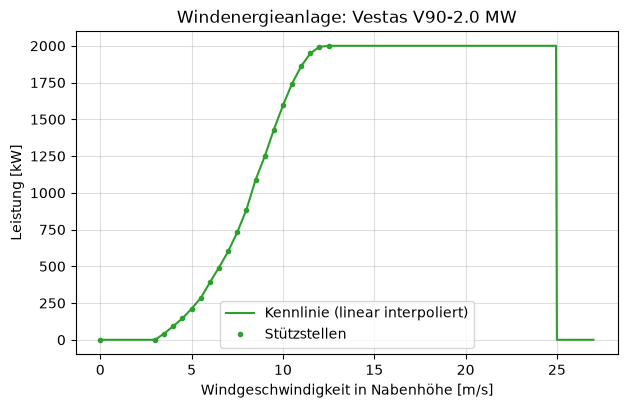

In [6]:
wt.plot_wind_curve()
plt.show()

### 1.3 PV-Anlage (Trina Solar Vertex S+ 460 W)

**Moduldaten:** Trina Solar Vertex S+ TSM-NEG9RC.27, bifaziales Glas-Glas-Modul (n-Typ, i-TOPCon), 144 Halbzellen, 1762 × 1134 mm (2,0 m²).

| Kenngröße | Wert | Quelle |
|---|---|---|
| Nennleistung P_STC (1000 W/m², 25 °C Zelltemperatur) | 460 W | [10] |
| Modulwirkungsgrad | 23,0 % | [10] |
| Temperaturkoeffizient von P_max (γ) | −0,29 %/K | [11] |
| NOCT (800 W/m², 20 °C Luft, 1 m/s Wind) | 43 °C | [11] |

Das Datenblatt [11] listet die Leistungsklassen 425–450 W; die Temperaturkennwerte gelten für die gesamte Modellfamilie und werden für die 460-W-Klasse übernommen.

**Umrechnung Einstrahlung → Leistung:**

1. *Einstrahlung auf die Modulebene:* Die API liefert direkt die Globalstrahlung auf die geneigte Fläche G (35°, Süd), sodass keine eigene Umrechnung von horizontaler auf geneigte Fläche nötig ist [6].
2. *Zelltemperatur* nach dem NOCT-Modell [12]:

   T_Zelle = T_Luft + (NOCT − 20 °C) / (800 W/m²) · G

3. *Leistung:* Die Modulleistung ist näherungsweise proportional zur Einstrahlung und nimmt mit steigender Zelltemperatur linear ab [12]:

   P_AC = P_STC · (G / 1000 W/m²) · [1 + γ · (T_Zelle − 25 °C)] · η_System

   mit η_System = 0,86 für Verluste in Wechselrichter, Leitungen, durch Verschmutzung und Fehlanpassung (Annahme; die Temperaturverluste sind bereits im Term mit γ enthalten).

**Beispiel:** Bei G = 1000 W/m² und 25 °C Lufttemperatur ist T_Zelle ≈ 53,8 °C und P_AC ≈ 363 W je Modul (0,79 kW/kWp).

**Vereinfachungen:** kein bifazialer Mehrertrag von der Rückseite, keine Verschattung, kein verändertes Verhalten bei schwacher Einstrahlung, keine Leistungsbegrenzung durch den Wechselrichter.

**Normierung:** Die Leistung wird je Modul (`pv_module_w`) und je kWp installierter Leistung (`pv_kw_per_kwp`) gespeichert. Eine Anlage mit z. B. 22 Modulen hat 22 × 0,46 kW = 10,12 kWp; ihre Leistung ist `pv_kw_per_kwp` × 10,12 kW.

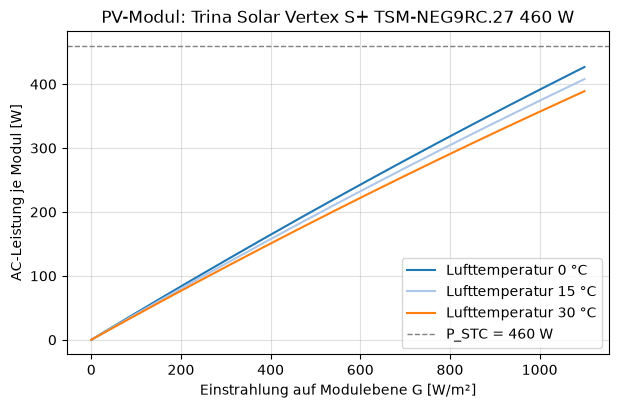

In [7]:
wt.plot_pv_curve()
plt.show()

### 1.4 Wetterdaten (Open-Meteo)

**Herkunft:** Die Wetterdaten stammen aus der *Historical Weather API* von Open-Meteo [4], [6]. Sie beruht auf Reanalyse-Datensätzen, in denen Messungen von Wetterstationen, Satelliten, Flugzeugen und Bojen mit einem numerischen Wettermodell zu einem lückenlosen Gitterdatensatz verbunden werden, unter anderem ERA5 des europäischen Wetterdienstes ECMWF [5].

**Abruf:** Standort 51,2° N, 7,34° E (Bergisches Land, NRW), Jahr 2025, stündliche Werte:

| Variable | Einheit | Bedeutung | Verwendung |
|---|---|---|---|
| `global_tilted_irradiance` | W/m² | Globalstrahlung auf eine geneigte Fläche (35° Neigung, Ausrichtung Süd), Mittel der vorangegangenen Stunde | PV |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe, Momentanwert | PV (Zelltemperatur) |
| `wind_speed_100m` | m/s | Windgeschwindigkeit in 100 m Höhe, Momentanwert | Wind |
| `shortwave_radiation` | W/m² | Globalstrahlung auf die horizontale Fläche | nur zur Information |

**Aufbereitung:**

1. Die API liefert Zeitstempel in UTC. Sie werden in lokale Zeit (Europe/Berlin) umgerechnet. Die Einstrahlung bezieht sich auf die vorangegangene Stunde und wird um eine Stunde verschoben, sodass alle Zeitstempel den Beginn der Stunde bezeichnen [6].
2. Aus den Wetterdaten wird über die Kennlinien die Leistung von PV und Wind berechnet (siehe unten).
3. **Typische Woche:** Für jeden Monat werden alle Wochen (Mo–So) betrachtet, die vollständig im Monat liegen, keine Zeitumstellung und keinen Feiertag enthalten. Gewählt wird die Woche, deren mittlere PV-Leistung und mittlere Windleistung zusammen am wenigsten vom Monatsmittel abweichen (Summe der relativen Abweichungen). So wird weder eine außergewöhnlich sonnige noch eine windstille Woche ausgewählt.
4. Ergebnis und Rohdaten werden als CSV gespeichert (`data/weather_weeks_2025.csv`, `data/weather_raw_2025.csv`).

**Tabelle der typischen Wochen** (erste Zeilen der Datei `weather_weeks_2025.csv`):

In [8]:
weather_table = pd.read_csv(WEATHER_FILE, index_col="time", parse_dates=True)
print(f"{len(weather_table)} Zeilen (12 Wochen × 168 Stunden), {weather_table.shape[1]} Spalten")
weather_table.head(10)

2016 Zeilen (12 Wochen × 168 Stunden), 10 Spalten


,month,hour_of_week,temperature_2m,global_tilted_irradiance,wind_speed_100m,wind_speed_hub,pv_module_w,pv_kw_per_kwp,wind_kw,wind_pu
time,,,,,,,,,,
2025-01-06 00:00:00,JANUARY,0,7.05,0.0000,11.7466,11.8288,0.0000,0.0000,1977.8195,0.9889
2025-01-06 01:00:00,JANUARY,1,7.15,0.0000,12.0354,12.1195,0.0000,0.0000,1994.9019,0.9975
2025-01-06 02:00:00,JANUARY,2,8.70,0.0000,11.6010,11.6821,0.0000,0.0000,1964.5629,0.9823
2025-01-06 03:00:00,JANUARY,3,8.55,0.0000,11.2695,11.3484,0.0000,0.0000,1921.7454,0.9609
2025-01-06 04:00:00,JANUARY,4,8.40,0.0000,11.6813,11.7630,0.0000,0.0000,1971.8745,0.9859
2025-01-06 05:00:00,JANUARY,5,8.20,0.0000,11.5412,11.6220,0.0000,0.0000,1959.1246,0.9796
2025-01-06 06:00:00,JANUARY,6,8.10,0.0000,12.6646,12.7532,0.0000,0.0000,2000.0000,1.0000
2025-01-06 07:00:00,JANUARY,7,8.15,0.0000,13.1477,13.2397,0.0000,0.0000,2000.0000,1.0000
2025-01-06 08:00:00,JANUARY,8,8.30,0.0000,13.6401,13.7355,0.0000,0.0000,2000.0000,1.0000


| Spalte | Einheit | Bedeutung |
|---|---|---|
| `time` | – | Beginn der Stunde, lokale Zeit (MEZ/MESZ) |
| `month`, `hour_of_week` | – | Monat (Enum `Month`), Stunde der Woche 0 … 167 (Mo 00:00 = 0) |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe |
| `global_tilted_irradiance` | W/m² | Einstrahlung auf die Modulebene (35°, Süd) |
| `wind_speed_100m`, `wind_speed_hub` | m/s | Windgeschwindigkeit in 100 m bzw. Nabenhöhe (105 m) |
| `pv_module_w` | W | AC-Leistung eines PV-Moduls (460 W) |
| `pv_kw_per_kwp` | kW/kWp | AC-Leistung je kWp |
| `wind_kw` | kW | Leistung der V90-2.0 MW |
| `wind_pu` | – | Leistung bezogen auf die Nennleistung |

In [9]:
def stats(series, *which):
    funcs = {"min": series.min, "Mittel": series.mean, "max": series.max}
    return [funcs[k]() for k in which]

rows = {}
for month, df in WEATHER.items():
    g_day_max = df["global_tilted_irradiance"].resample("D").max()      # Tageshöchstwert der Einstrahlung
    rows[month.label] = {
        ("Woche", "ab"): df.index[0].strftime("%a %d.%m.%Y"),
        **dict(zip([("T_Luft [°C]", k) for k in ("min", "Mittel", "max")],
                   stats(df["temperature_2m"], "min", "Mittel", "max"))),
        ("G_Modul [W/m²]", "Mittel"): df["global_tilted_irradiance"].mean(),
        ("G_Modul [W/m²]", "Tagesmax. min"): g_day_max.min(),
        ("G_Modul [W/m²]", "max"): g_day_max.max(),
        **dict(zip([("Wind Nabe [m/s]", k) for k in ("min", "Mittel", "max")],
                   stats(df["wind_speed_hub"], "min", "Mittel", "max"))),
        ("PV-Modul [W]", "Mittel"): df["pv_module_w"].mean(),
        ("PV-Modul [W]", "max"): df["pv_module_w"].max(),
        ("PV-Modul [W]", "Energie [kWh/Woche]"): df["pv_module_w"].sum() / 1000,
        **dict(zip([("WEA [MW]", k) for k in ("min", "Mittel", "max")],
                   [v / 1000 for v in stats(df["wind_kw"], "min", "Mittel", "max")])),
        ("WEA [MW]", "Energie [MWh/Woche]"): df["wind_kw"].sum() / 1000,
        ("WEA [MW]", "Stunden Stillstand"): int((df["wind_kw"] <= 0).sum()),
    }
overview = pd.DataFrame(rows).T
overview.columns = pd.MultiIndex.from_tuples(overview.columns)
num = overview.columns.drop(("Woche", "ab"))
overview[num] = overview[num].astype(float)
plots.table(overview, decimals=1, int_cols=[("WEA [MW]", "Stunden Stillstand")])

Zur Tabelle: Die Einstrahlung ist nachts immer 0 W/m², ein Minimum über die Woche sagt deshalb nichts aus. Stattdessen steht unter **Tagesmax. min** der höchste Wert des trübsten Tages und unter **max** der höchste Wert des sonnigsten Tages. Bei der WEA zählt **Stunden Stillstand** die Stunden mit einer Windgeschwindigkeit unter der Einschaltgeschwindigkeit (4 m/s), in denen die Anlage keine Leistung abgibt. Die Leistungswerte gelten für ein PV-Modul (460 W) bzw. eine WEA (2,0 MW). Im CIGRE-Netz werden sie mit der installierten Leistung skaliert (siehe 3.2).

**Wetterdiagramme:** Für jeden Monat zeigt ein zweiteiliges Diagramm die typische Woche:

- **oben:** Windgeschwindigkeit in Nabenhöhe [m/s], Lufttemperatur [°C] und Einstrahlung auf die Modulebene [100 W/m²]
- **unten:** Leistung der Windenergieanlage [MW] und eines PV-Moduls [100 W]

Die Einstrahlung und die PV-Leistung sind so skaliert, dass alle Größen im selben Zahlenbereich liegen: Ein Wert von 2 im unteren Diagramm entspricht 2 MW der Windenergieanlage bzw. 200 W des PV-Moduls, ein Wert von 8 im oberen Diagramm entspricht 800 W/m² Einstrahlung.

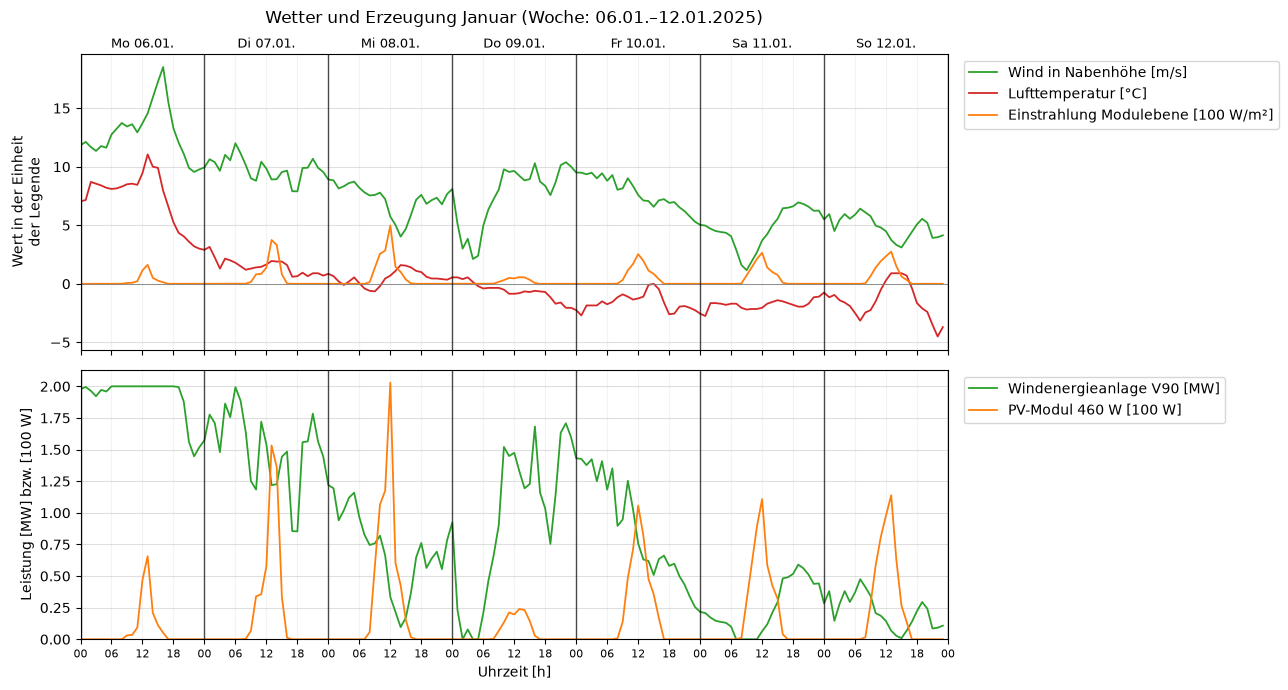

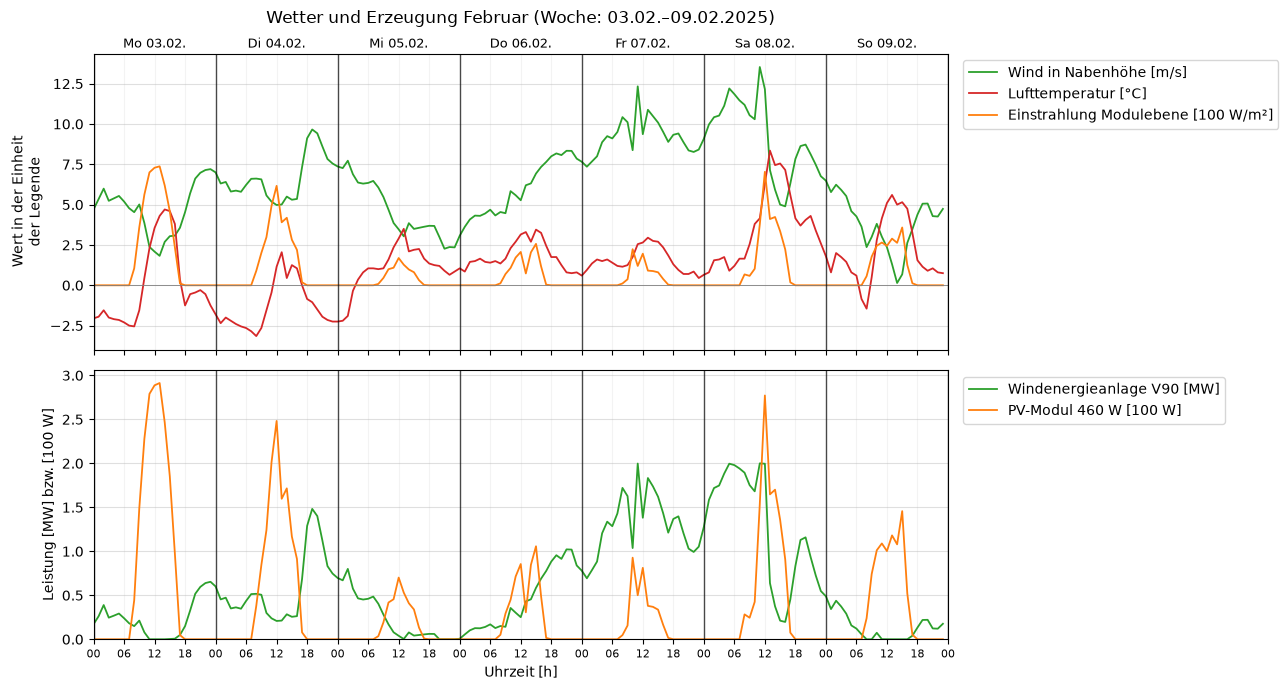

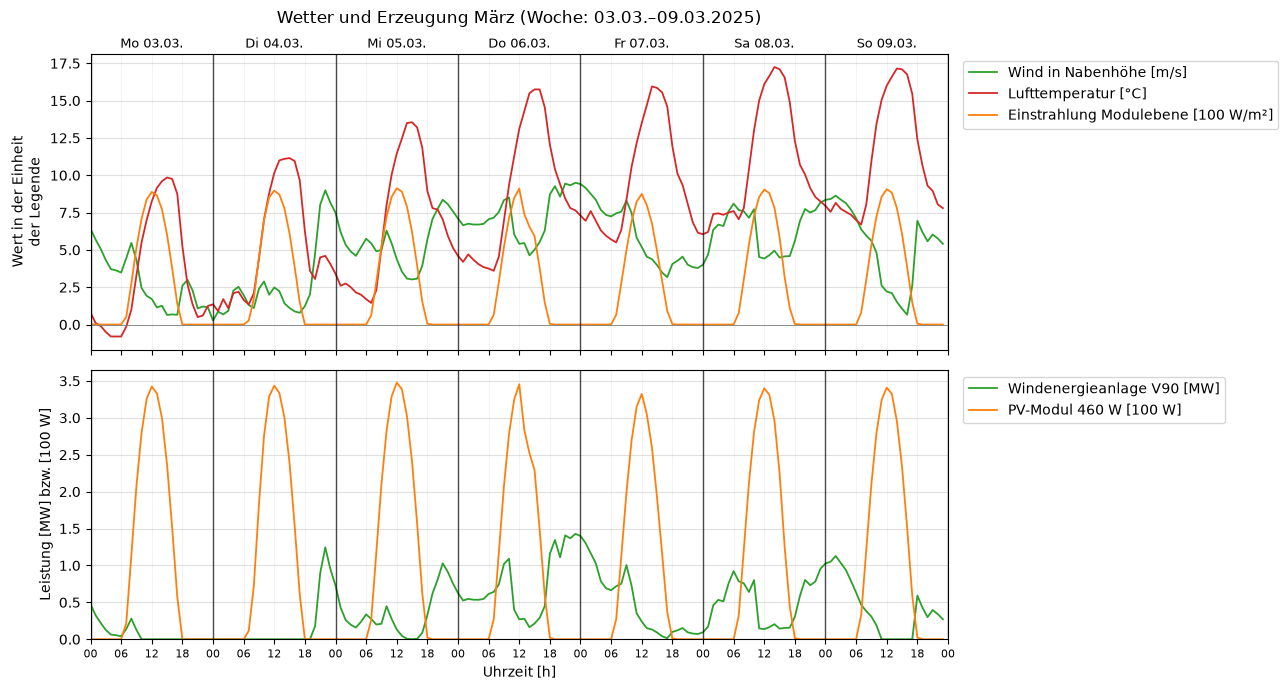

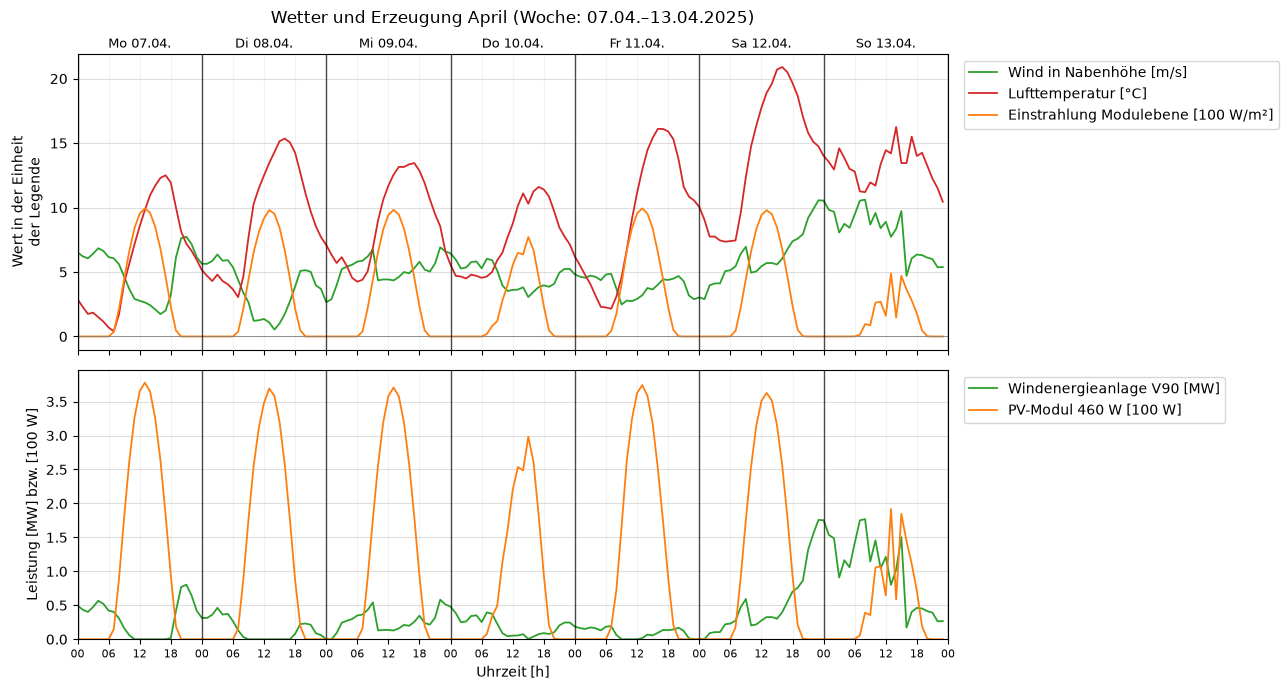

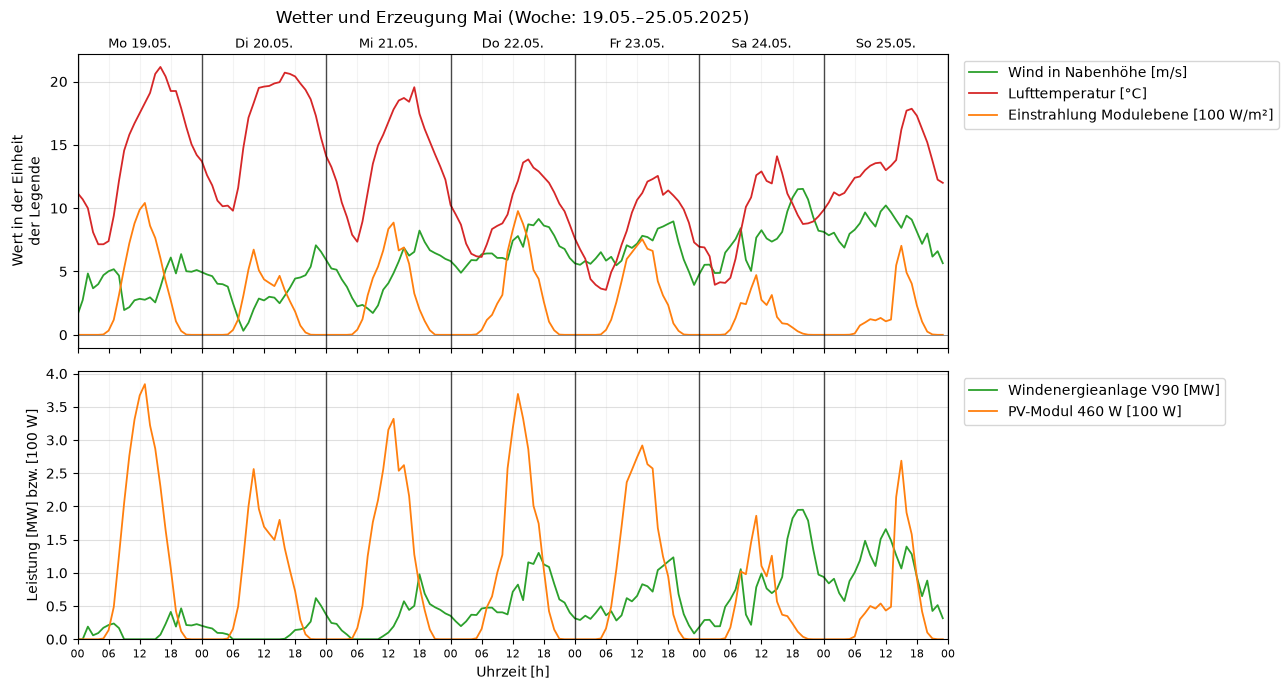

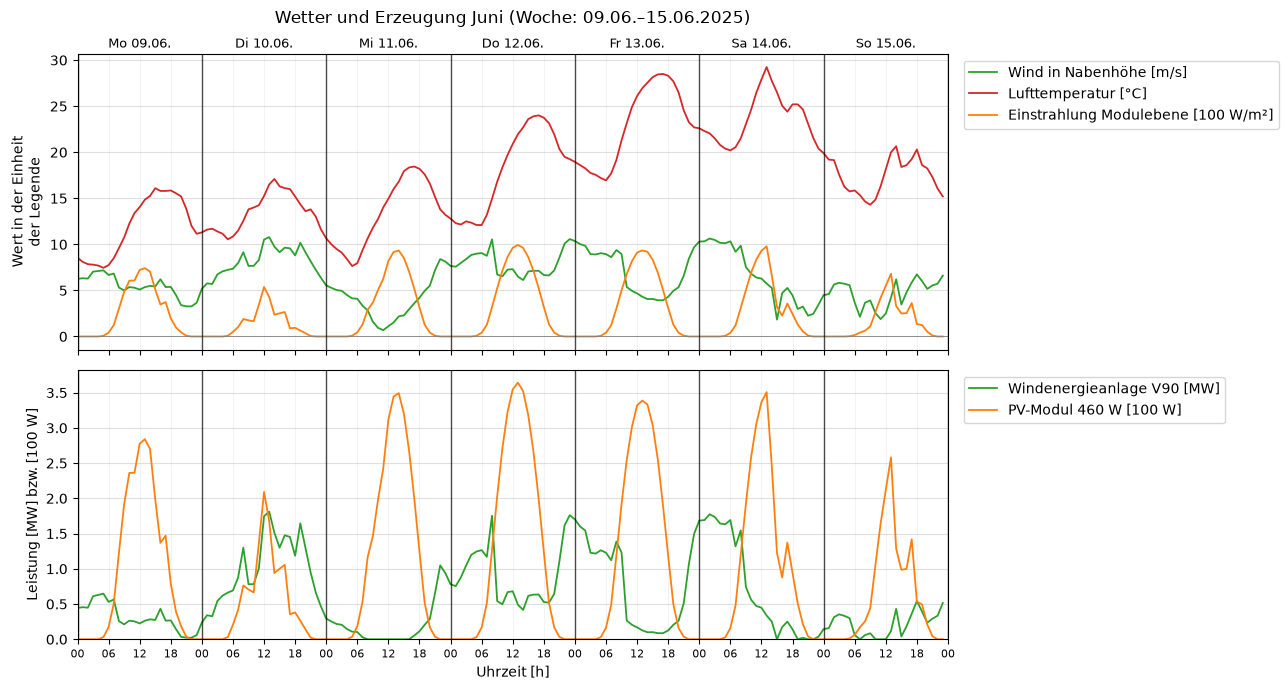

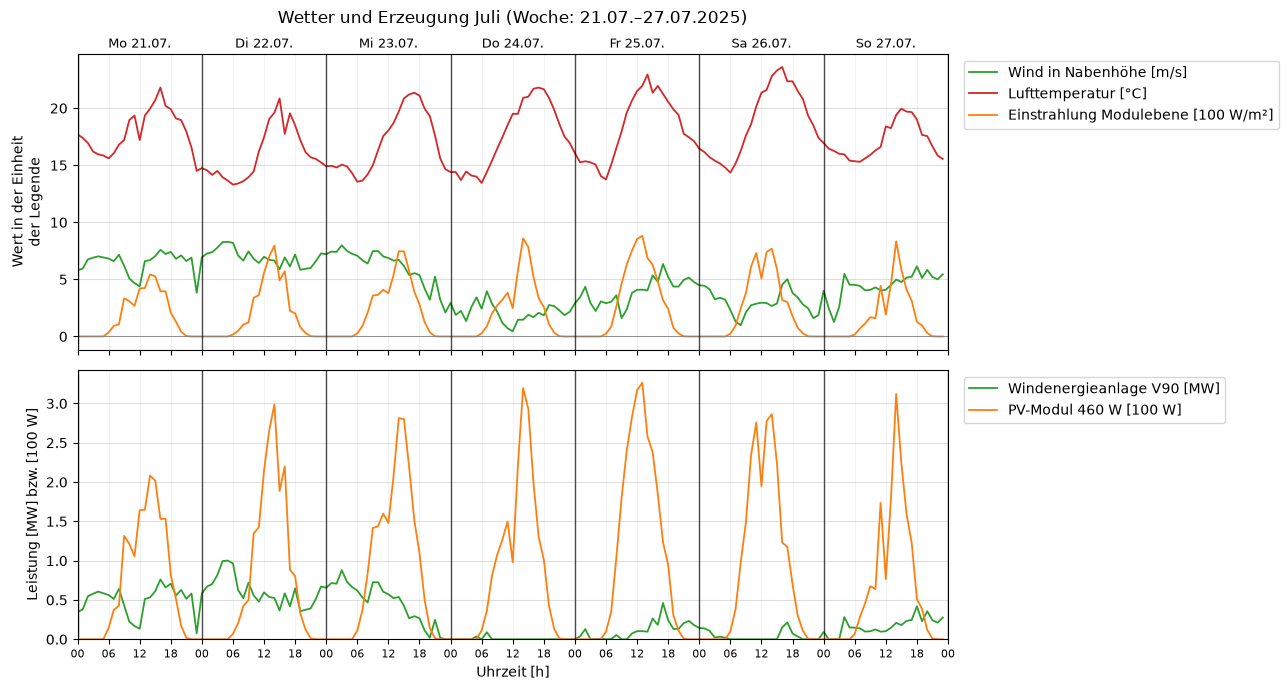

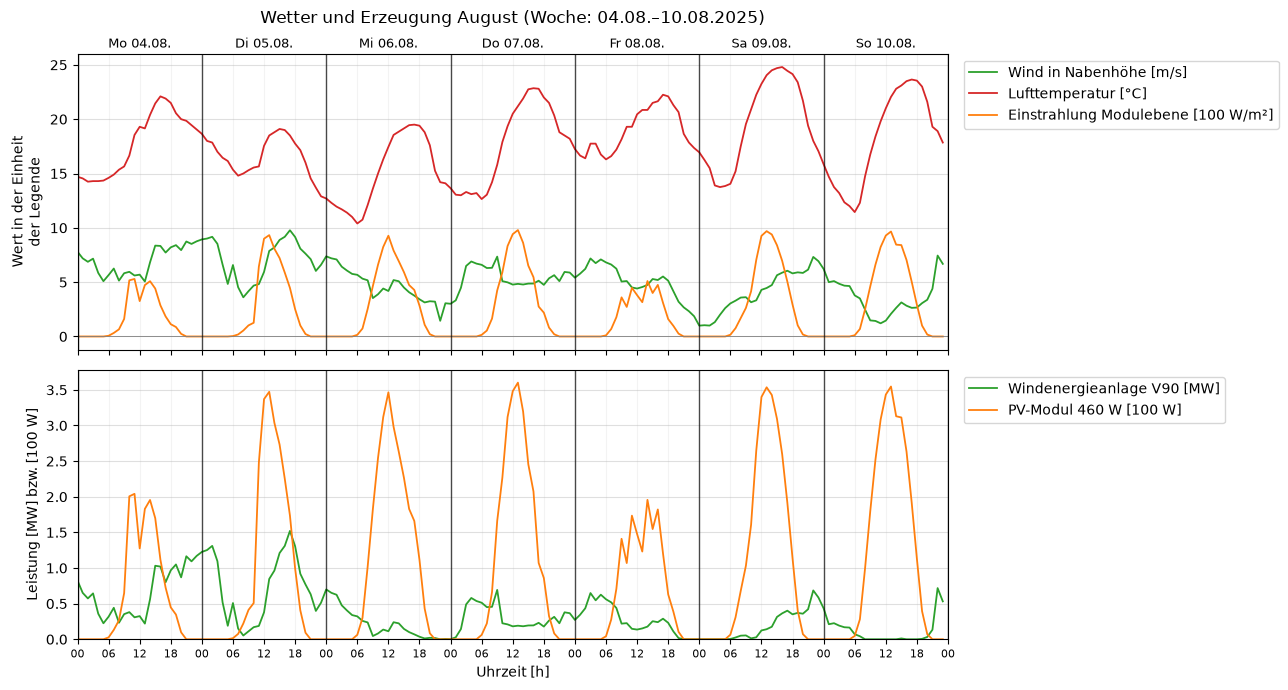

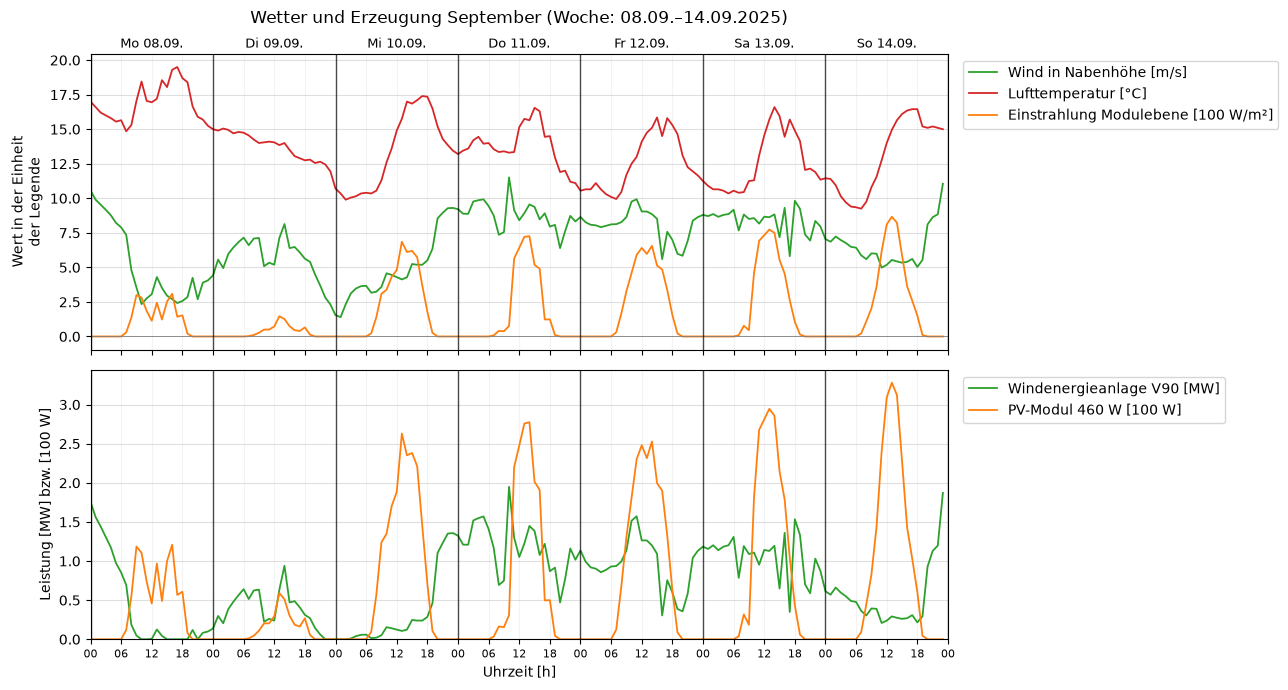

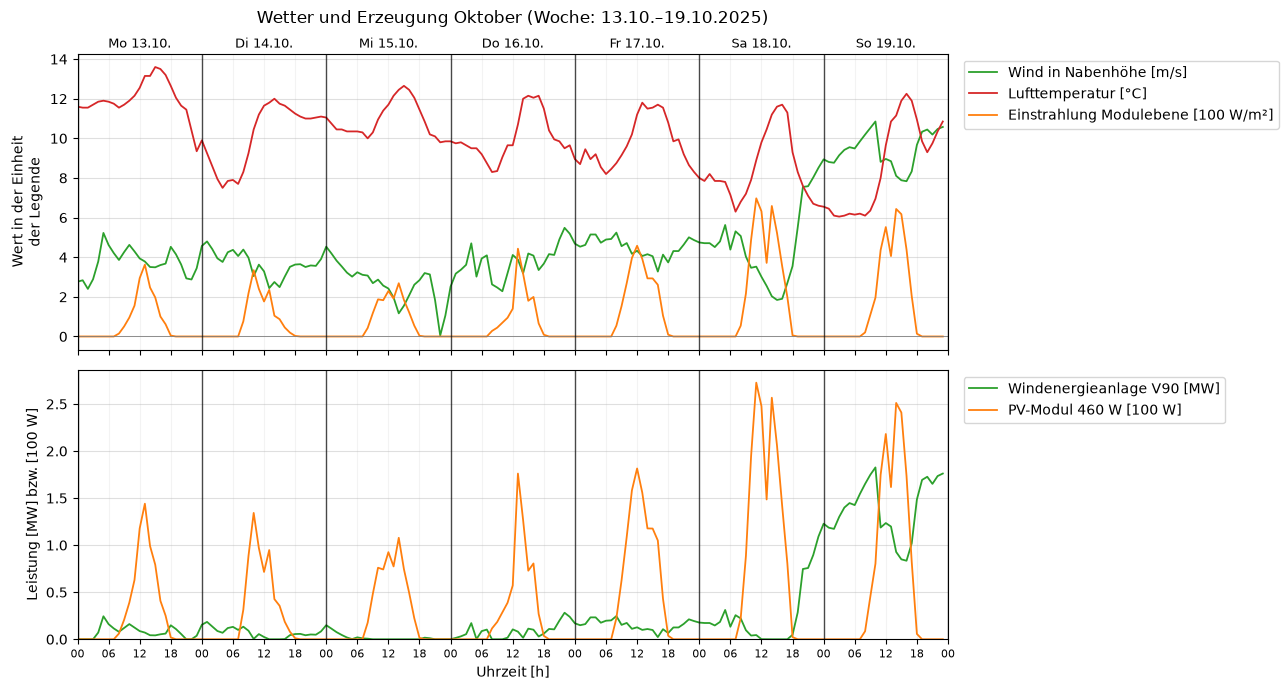

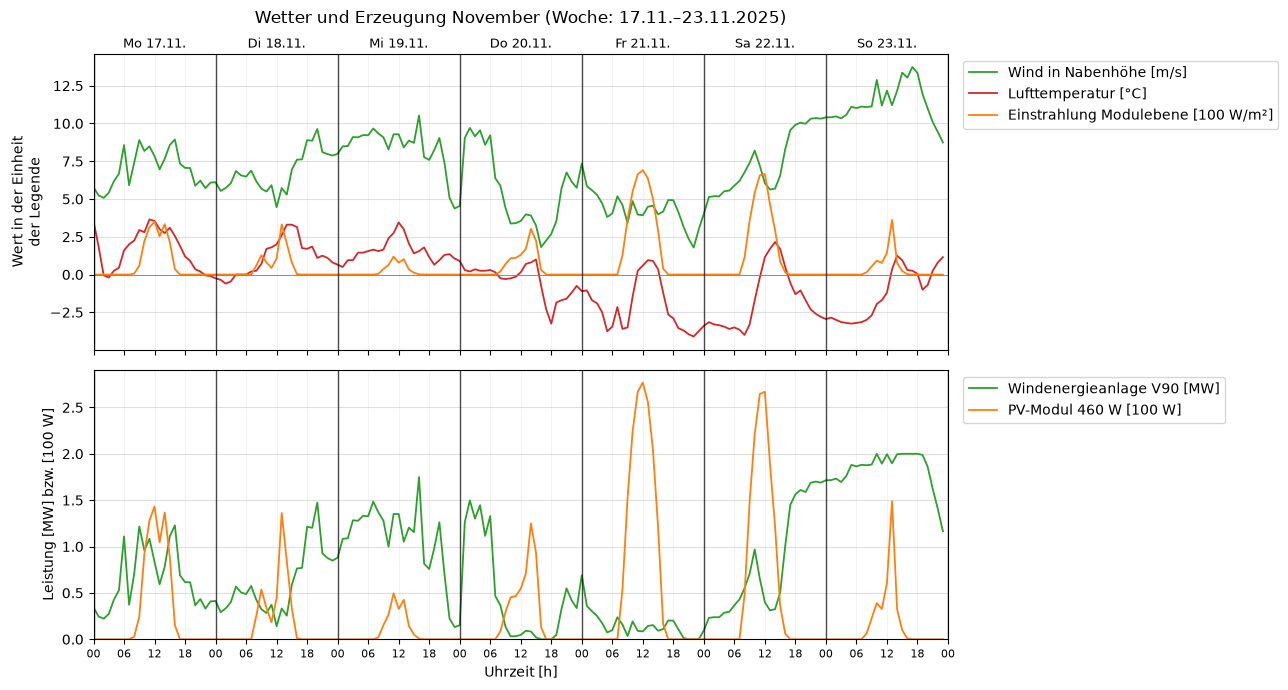

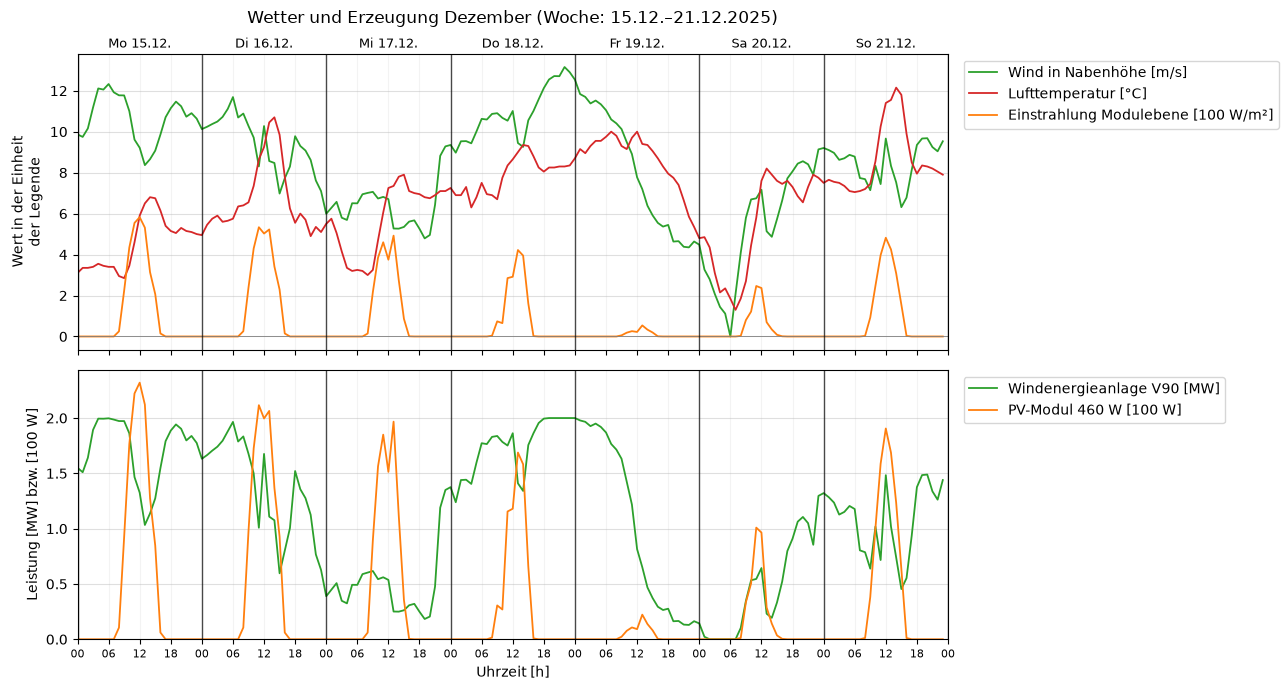

In [10]:
for month, w in WEATHER.items():
    plots.plot_weather_week(w, f"Wetter und Erzeugung {month.label} "
                               f"(Woche: {w.index[0]:%d.%m.}–{w.index[-1]:%d.%m.%Y})")
    plt.show()

### 1.5 Erzeugungsanlagen für die Szenarien in Task 4

| Anlage | Größe | Grundlage | Begründung |
|---|---|---|---|
| Windpark | 15 × Vestas V90-2.0 MW = 30 MW | Kennlinie und Wind auf Nabenhöhe aus 1.2 und 1.4 | Der Arbeitsauftrag gibt 15 WEA vor. Alle Anlagen erhalten dieselbe Windgeschwindigkeit (gleichzeitige Einspeisung). |
| PV-Freiflächenanlage | 10 MWp | PV-Leistung je kWp aus 1.3 und 1.4 | PV-Freiflächenanlagen sind Anlagen ab 1 MWp; die 18 Zuschläge der Innovationsausschreibung im April 2021 hatten zusammen 258 MW PV-Leistung, also im Mittel rund 14 MWp [22]. |

**Plausibilitätsprüfung der Erträge:** Aus den 12 typischen Wochen wird der Jahresertrag hochgerechnet (mittlere Wochenenergie × 52,14) und mit Literaturwerten verglichen. Für PV nennt [22] einen spezifischen Jahresertrag von 935 (Norden), 1105 (Mitte) und 1280 kWh/kWp (Süden) bei optimaler Neigung und Südausrichtung.

In [11]:
wochen = len(WEATHER)
pv_ertrag = sum(df["pv_kw_per_kwp"].sum() for df in WEATHER.values()) / wochen * 52.14        # kWh/kWp/a
wind_vlh = sum(df["wind_pu"].sum() for df in WEATHER.values()) / wochen * 52.14                # Volllaststunden
ertrag = pd.DataFrame({
    "Kennwert": ["spezifischer Ertrag [kWh/kWp/a]", "Volllaststunden [h/a]"],
    "Simulation": [pv_ertrag, wind_vlh],
    "Jahresenergie Anlage [GWh/a]": [pv_ertrag * 10_000 / 1e6, wind_vlh * 30 / 1000],
}, index=["PV-Freiflächenanlage 10 MWp", "Windpark 30 MW"])
ertrag.round(1)

,Kennwert,Simulation,Jahresenergie Anlage [GWh/a]
PV-Freiflächenanlage 10 MWp,spezifischer Ertrag [kWh/kWp/a],1222.6,12.2
Windpark 30 MW,Volllaststunden [h/a],2515.9,75.5


**Einordnung:** Der hochgerechnete PV-Ertrag liegt mit rund 1220 kWh/kWp zwischen den Werten für Mittel- und Süddeutschland in [22] und damit etwas über dem Wert für die Mitte. Gründe: optimale Ausrichtung im Modell, keine Verschmutzungs- und Verfügbarkeitsverluste und die Hochrechnung aus nur 12 typischen Wochen. Der Windpark erreicht rund 2500 Volllaststunden; das ist für einen Binnenlandstandort eher hoch, weil die Wetterwochen nach mittlerer Erzeugung ausgewählt wurden und weder Abschattung im Park noch Verfügbarkeitsverluste berücksichtigt sind. Beide Werte sind für die Netzuntersuchung ausreichend genau; entscheidend sind die Leistungsspitzen und ihre Gleichzeitigkeit mit der Last.

### 1.6 Haushalte mit PV-Anlage und Batteriespeicher (Ortsnetz)

Für das Ortsnetz-Szenario werden Haushalte mit PV-Anlage und teilweise mit Batteriespeicher abgebildet. Die Haushalte behalten ihren Verbrauch (Profil H25); PV-Anlage und Speicher kommen als eigene Elemente hinzu. So entsteht echte Einspeisung ins Ortsnetz, und die Vorzeichen sind eindeutig: Last `p_mw > 0` = Bezug, Erzeuger `p_mw > 0` = Einspeisung, Speicher `p_mw > 0` = Laden, `p_mw < 0` = Entladen (pandapower-Konvention [17]).

| Kenngröße | Wert | Grundlage |
|---|---|---|
| Jahresverbrauch je Haushalt | 3000 kWh/a | durchschnittlicher Drei-Personen-Haushalt in einer Wohnung bis 3000 kWh/a [32]; daraus die Zahl der Haushalte je Last |
| PV-Leistung je Haushalt mit PV | 9 kWp | Median der HTW-Feldmessung 8,4 kWp (4,8 bis 13 kWp) [34]; geförderte private Anlagen mit Speicher in Baden-Württemberg im Mittel 10,7 kWp [37]; Anlagen von 10 bis 20 kWp machen seit 2023 einen ebenso großen Teil des Zubaus aus wie 2 bis 10 kWp [36] |
| Speicherkapazität je Heimspeicher | 8,3 kWh | durchschnittliche Größe neu installierter Heimspeicher Q1 2026 [33]; HTW-Feldmessung: Median 7,3 kWh [34] |
| Lade-/Entladeleistung | 0,59 kW je kWh, also 4,9 kW | mittleres Verhältnis von Nennleistung zu nutzbarer Kapazität [34], [38] |
| Wirkungsgrad je Richtung | 0,95 (Zyklus ≈ 0,90) | Umwandlungswirkungsgrade beim Laden und Entladen 92 bis 98 % [35] |
| Ladezustand zu Beginn jeder Woche | 0 % | Annahme; die typischen Wochen hängen zeitlich nicht zusammen |
| Anteil der Haushalte (heute) | 15 % mit PV, davon 6,7 % aller Haushalte mit Speicher | KfW-Energiewendebarometer [23] |
| Anteil der Haushalte (Zukunft) | 50 % mit PV, davon 40 % aller Haushalte mit Speicher | Annahme: hoher Ausbau; fast 80 % der neuen privaten Aufdachanlagen werden mit Speicher gebaut [24] |
| Leistungsfaktor PV | cos φ = 1 | vereinfachend; VDE-AR-N 4105 erlaubt dem Netzbetreiber Vorgaben zur Blindleistung [30] |

**Regelung des Speichers (Eigenverbrauch):** Je Stunde wird die PV-Leistung der Haushalte mit Speicher mit deren Verbrauch verglichen. Ein Überschuss wird geladen, höchstens mit der Speicherleistung und bis der Speicher voll ist; ein Defizit wird aus dem Speicher gedeckt, bis er leer ist. Erst was der Speicher nicht aufnehmen oder liefern kann, fließt ins Netz bzw. kommt aus dem Netz. Die Regelung misst nur am Hausanschluss und kennt das Netz nicht (`timeseries.eigenverbrauch`, verwendet in der Simulation über das Element `Storage`).

**Beispiel:** ein Haushalt mit 3000 kWh/a, 9 kWp und 8,3 kWh Speicher in der typischen Januar- und Juliwoche.

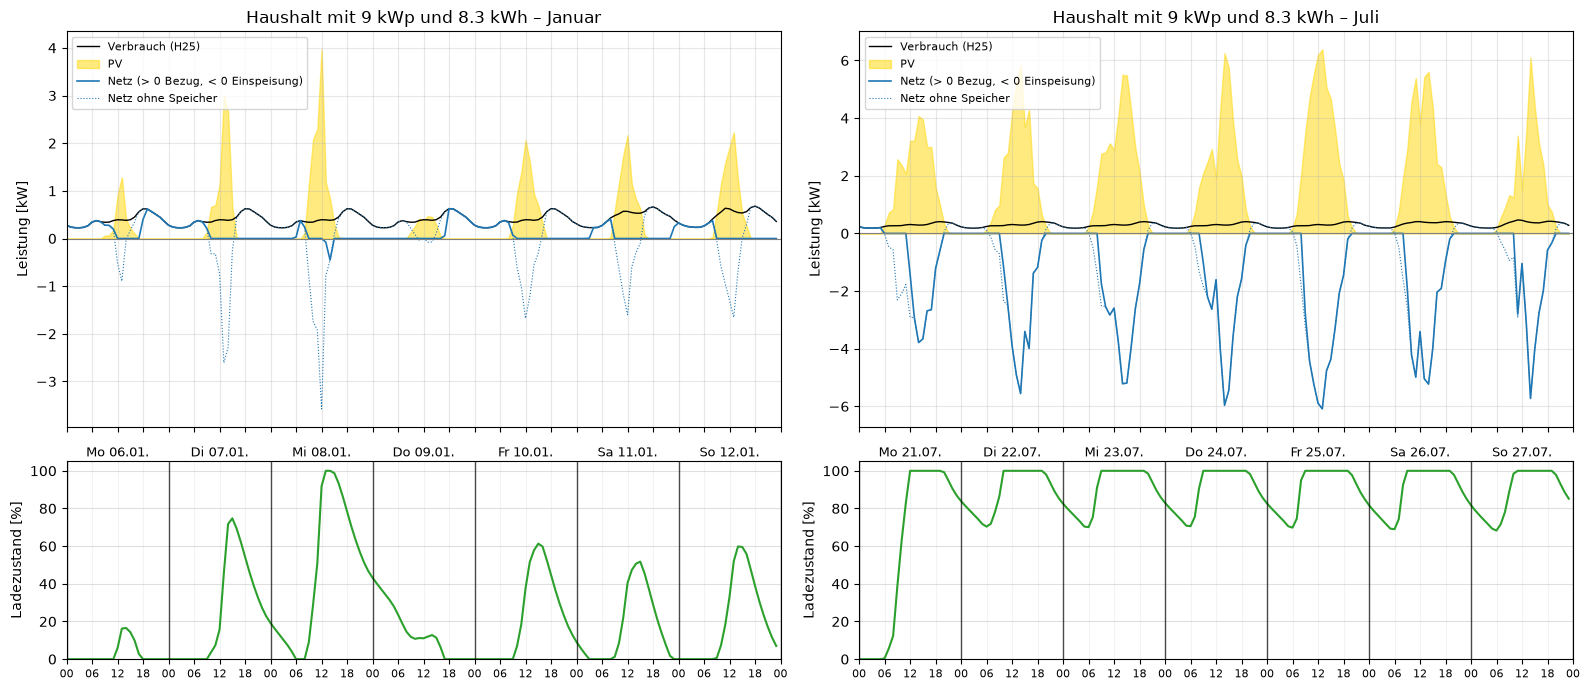

In [12]:
import timeseries as tsm
import lvnetz

hh_kwh, kwp, e_kwh = lvnetz.KWH_JE_HAUSHALT, lvnetz.KWP_JE_HAUSHALT, lvnetz.SPEICHER_KWH
p_kw, eta = e_kwh * lvnetz.SPEICHER_KW_JE_KWH, lvnetz.SPEICHER_ETA

def haushalt_woche(month):
    last = pr.build_week(PROFILES, Lastprofil.HAUSHALT, month, annual_kwh=hh_kwh, unit="kW",
                         start=WEEK_STARTS[month], resolution="1h")
    pv = pd.Series(WEATHER[month]["pv_kw_per_kwp"].to_numpy() * kwp, index=last.index)
    p, soc = tsm.eigenverbrauch(pv.to_numpy(), last.to_numpy(), e_kwh, p_kw, eta)
    netz = last - pv + p                                   # > 0 Bezug, < 0 Einspeisung (alle Werte in kW)
    return pd.DataFrame({"Verbrauch [kW]": last, "PV [kW]": pv, "Speicher [kW]": p, "Ladezustand [%]": soc,
                         "Netz [kW]": netz, "Netz ohne Speicher [kW]": last - pv})

fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharex="col", gridspec_kw={"height_ratios": [2, 1]})
for j, month in enumerate((Month.JANUARY, Month.JULY)):
    w = haushalt_woche(month)
    ax = axes[0, j]
    ax.plot(w.index, w["Verbrauch [kW]"], color="black", lw=1, label="Verbrauch (H25)")
    ax.fill_between(w.index, w["PV [kW]"], color="gold", alpha=0.5, label="PV")
    ax.plot(w.index, w["Netz [kW]"], color="tab:blue", lw=1.2, label="Netz (> 0 Bezug, < 0 Einspeisung)")
    ax.plot(w.index, w["Netz ohne Speicher [kW]"], color="tab:blue", lw=0.8, ls=":", label="Netz ohne Speicher")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylabel("Leistung [kW]")
    ax.set_title(f"Haushalt mit {kwp:.0f} kWp und {e_kwh} kWh – {month.label}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
    axes[1, j].plot(w.index, w["Ladezustand [%]"], color="tab:green")
    axes[1, j].set_ylabel("Ladezustand [%]")
    axes[1, j].set_ylim(0, 105)
    axes[1, j].grid(alpha=0.3)
    plots.week_axis(axes[1, j], w.index)
plt.tight_layout()
plt.show()

In [13]:
zeilen = {}
for month in Month:
    w = haushalt_woche(month)
    pv, last = w["PV [kW]"].sum(), w["Verbrauch [kW]"].sum()
    bezug, einsp = w["Netz [kW]"].clip(lower=0).sum(), (-w["Netz [kW]"]).clip(lower=0).sum()
    bezug0, einsp0 = w["Netz ohne Speicher [kW]"].clip(lower=0).sum(), (-w["Netz ohne Speicher [kW]"]).clip(lower=0).sum()
    zeilen[month.label] = {"Verbrauch [kWh]": last, "PV [kWh]": pv, "Bezug ohne Speicher [kWh]": bezug0,
                           "Bezug mit Speicher [kWh]": bezug, "Einspeisung ohne Speicher [kWh]": einsp0,
                           "Einspeisung mit Speicher [kWh]": einsp}
bilanz = pd.DataFrame(zeilen).T
bilanz.loc["Summe 12 Wochen"] = bilanz.sum()
s = bilanz.loc["Summe 12 Wochen"]
bilanz["Autarkie mit Speicher [%]"] = 100 * (1 - bilanz["Bezug mit Speicher [kWh]"] / bilanz["Verbrauch [kWh]"])
bilanz["Autarkie ohne Speicher [%]"] = 100 * (1 - bilanz["Bezug ohne Speicher [kWh]"] / bilanz["Verbrauch [kWh]"])
plots.table(bilanz, decimals=1)

,Verbrauch [kWh],PV [kWh],Bezug ohne Speicher [kWh],Bezug mit Speicher [kWh],Einspeisung ohne Speicher [kWh],Einspeisung mit Speicher [kWh],Autarkie mit Speicher [%],Autarkie ohne Speicher [%]
Januar,68.2,52.7,48.0,19.7,32.5,0.5,71.2,29.6
Februar,66.9,121.1,41.6,5.2,95.8,50.8,92.2,37.8
März,61.4,317.8,32.0,1.7,288.3,249.2,97.2,48.0
April,57.9,335.1,24.5,1.7,301.6,269.6,97.1,57.7
Mai,50.8,283.0,17.1,1.1,249.2,224.2,97.8,66.3
Juni,50.1,313.7,15.3,1.1,278.8,255.5,97.7,69.5
Juli,50.0,265.3,16.7,1.2,232.0,207.4,97.6,66.6
August,48.8,306.2,18.0,1.4,275.4,249.6,97.2,63.1
September,50.2,205.8,23.2,1.4,178.8,148.0,97.2,53.8
Oktober,56.3,131.5,31.4,2.0,106.7,68.2,96.5,44.2


**Einordnung:** Ohne Speicher deckt die PV-Anlage den Verbrauch nur tagsüber; der Überschuss mittags fließt ins Netz, abends und nachts wird bezogen. Der Speicher verschiebt einen Teil des Mittagsüberschusses in den Abend. Im Sommer ist er fast jeden Tag voll, sodass mittags trotzdem eingespeist wird; im Winter reicht die PV-Erzeugung oft nicht, um ihn zu füllen. Für das Netz heißt das: Der Speicher senkt den Bezug am Abend, die Einspeisespitze am Mittag senkt er an sonnigen Tagen kaum, weil er dann schon vormittags voll ist.

## 2 Netzdaten

Die Netzmodelle werden in den Teil-Notebooks beschrieben, dort, wo sie verwendet werden:

- **CIGRE-Mittelspannungsnetz** (`pn.create_cigre_network_mv(with_der=False)`, Baseline ohne dezentrale Erzeuger) [13], [14]: Topologie, Betriebsmittel, Nennspannungen und Betriebspunkte in `Task4-1_Baseline.ipynb`.
- **CIGRE-Niederspannungsnetz** (`pn.create_cigre_network_lv()`) [13], Leitungstypen und Stromgrenzen [18]: `Task4-2_Ortsnetz.ipynb`; Auslegung der Ortsnetztrafos und Leitungen: `Task4-3_Ortsnetz_Auslegung.ipynb`.

Die Datenquellen der Netze stehen im Quellenverzeichnis (Abschnitt 3).

## 3 Quellenverzeichnis

Zentrales Verzeichnis für alle Notebooks von Task 4. Die Notebooks verwenden dieselben Nummern und führen am Ende jeweils die von ihnen zitierten Quellen auf.

**Lastprofile und Verbrauch**

[1] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[2] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Repräsentative Profile BDEW H25, G25, L25, P25, S25 – Veröffentlichung“, Datensatz (CSV), Berlin, 2025.

[3] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Anwendung der Repräsentativen VDEW-Lastprofile step-by-step“, Berlin, 2000, S. 18 f. Online: https://www.bdew.de/media/documents/2000131_Anwendung-repraesentativen_Lastprofile-Step-by-step.pdf

[32] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Stromverbrauch vergleichen und Sparpotenzial nutzen“, Presseinformation, 21.04.2016. Online: https://www.bdew.de/presse/presseinformationen/stromverbrauch-vergleichen-und-sparpotenzial-nutzen/

**Wetter, Wind- und PV-Anlagen**

[4] P. Zippenfenig, „Open-Meteo.com Weather API“, Zenodo, 2023, doi: 10.5281/ZENODO.7970649.

[5] H. Hersbach et al., „The ERA5 global reanalysis“, Quarterly Journal of the Royal Meteorological Society, Bd. 146, Nr. 730, S. 1999–2049, 2020, doi: 10.1002/qj.3803.

[6] Open-Meteo, „Historical Weather API – Documentation“. Online: https://open-meteo.com/en/docs/historical-weather-api (Abruf: 14.10.2026).

[7] wind-turbine-models.com, „Vestas V90“. Online: https://www.wind-turbine-models.com/turbines/16-vestas-v90 (Abruf: 14.10.2026).

[8] windpowerlib, Version 0.2.2, Turbinendatenbank der Open Energy Database (Datei `oedb/power_curves.csv`, Eintrag „V90/2000“). Online: https://github.com/wind-python/windpowerlib

[9] E. Hau, *Windkraftanlagen: Grundlagen, Technik, Einsatz, Wirtschaftlichkeit*, 6. Aufl. Berlin, Heidelberg: Springer Vieweg, 2016.

[10] Trina Solar, „Vertex S+ NEG9RC.27“, Produktseite. Online: https://www.trinasolar.com/de/NEG9RC.27/ (Abruf: 14.10.2026).

[11] Trina Solar, „Vertex S+ – Bifaziales Doppelglas N-Typ i-TOPCon Modul, TSM-NEG9RC.27“, Datenblatt, Version TSM_DE_2024_B, 2024. Online: https://www-cdn.trinasolar.com/wwwstorage/sites/8/250227_Datasheet_VertexS_NEG9RC.27_DE_2024_B_web.pdf

[12] J. A. Duffie und W. A. Beckman, *Solar Engineering of Thermal Processes*, 4. Aufl. Hoboken, NJ: Wiley, 2013.

[22] C. Kost et al., „Stromgestehungskosten Erneuerbare Energien“, Fraunhofer ISE, Freiburg, Juni 2021, Tabelle 3, S. 14. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/DE2021_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf

[24] Fraunhofer ISE, „Photovoltaics Report“, Freiburg. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/Photovoltaics-Report.pdf

**Haushalte mit PV und Speicher**

[23] KfW Research, „Fast 13 Millionen Haushalte nutzen Energiewendetechnologien“, Pressemitteilung, 12.09.2024 (KfW-Energiewendebarometer). Online: https://www.kfw.de/%C3%9Cber-die-KfW/Newsroom/Aktuelles/Pressemitteilungen-Details_821696.html

[33] RWTH Aachen, Institut für Stromrichtertechnik und Elektrische Antriebe (ISEA), „Battery Charts“, Auswertung des Marktstammdatenregisters, Methodik. Online: https://battery-charts.de/de/battery-charts-de/; Quartalswerte Q1 2026 nach pv magazine, 08.05.2026. Online: https://www.pv-magazine.de/2026/05/08/starkes-wachstum-im-grossspeichermarkt-fuehrt-zu-batterie-rekordzubau-von-ueber-2-gigawattstunden-im-1-quartal-2026/

[34] Meissner et al. (HTW Berlin), „Feldmessdaten von 110 PV-Speichersystemen“, 2024. Online: https://solar.htw-berlin.de/wp-content/uploads/MEISSNER-2024-Feldmessdaten-von-110-PV-Speichersystemen.pdf

[35] HTW Berlin, „Stromspeicher-Inspektion 2025“, Berlin, 2025. Online: https://solar.htw-berlin.de/wp-content/uploads/HTW-Stromspeicher-Inspektion-2025.pdf; Zusammenfassung: Solarserver, 07.02.2025. Online: https://www.solarserver.de/2025/02/07/stromspeicher-inspektion-2025-neue-wirkungsgradrekorde-von-kostal-und-sax-power/

[36] Fraunhofer ISE, Presseinformation zur Kurzstudie über den Zuwachs von Batteriespeichern und Balkon-PV in Deutschland, Freiburg, 2024. Online: https://www.ise.fraunhofer.de/de/presse-und-medien/presseinformationen/2024/kurzstudie-zuwachs-von-batteriespeichern-und-balkon-pv-in-deutschland.html

[37] RWTH Aachen und LUBW, „Speichermonitoring BW 2.0“, Karlsruhe. Online: https://pudi.lubw.de/detailseite/-/publication/10501-Speichermonitoring_BW_2.0.pdf

**Netzmodelle und Software**

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[14] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

[17] pandapower, „Datastructure and Elements“, Dokumentation der Elemente und Ergebnistabellen (res_bus, res_line, res_trafo, res_ext_grid, res_storage). Online: https://pandapower.readthedocs.io/en/latest/elements.html

[18] *Smart Energy Management for Smart Grid*, Basel: MDPI Books, Tabelle der Leitungstypen des CIGRE-LV-Netzes (Querschnitt, R und L von Phasen- und Neutralleiter, Bemessungsstrom). Online: https://mdpi-res.com/bookfiles/book/7980/Smart_Energy_Management_for_Smart_Grid.pdf

[25] pandapower, „Standard Type Libraries“ und `create_cigre_network_mv`, Dokumentation, Version 3.x. Online: https://pandapower.readthedocs.io

**Normen, Regelwerke und Gesetze**

[15] DIN EN 50160, „Merkmale der Spannung in öffentlichen Elektrizitätsversorgungsnetzen“ (EN 50160:2010 mit Änderungen), Berlin: Beuth.

[26] Zuhmann, „Mittelspannungskabel NA2XS2Y nach VDE 0276-620“, Datenblatt (Ausgabe 13.07.2016). Online: https://www.zuhmann.info/media/daten/019.pdf

[27] DIN VDE 0276-620 (VDE 0276-620), „Starkstromkabel – Energieverteilungskabel mit extrudierter Isolierung für Nennspannungen von 3,6/6 (7,2) kV bis einschließlich 20,8/36 (42) kV“, Berlin: VDE Verlag.

[28] DIN VDE 0276-1000 (VDE 0276-1000), „Starkstromkabel – Strombelastbarkeit, Allgemeines, Umrechnungsfaktoren“, Berlin: VDE Verlag.

[29] DIN IEC 60076-7 (VDE 0532-76-7), „Leistungstransformatoren – Teil 7: Belastungsrichtlinie für ölgefüllte Leistungstransformatoren“, Berlin: VDE Verlag.

[30] VDE-AR-N 4105, „Erzeugungsanlagen am Niederspannungsnetz – Technische Mindestanforderungen für Anschluss und Parallelbetrieb von Erzeugungsanlagen am Niederspannungsnetz“, Berlin: VDE Verlag, 2018.

[31] VDE-AR-N 4110, „Technische Regeln für den Anschluss von Kundenanlagen an das Mittelspannungsnetz und deren Betrieb (TAR Mittelspannung)“, Berlin: VDE Verlag, 2023.

[39] Gesetz über die Elektrizitäts- und Gasversorgung (Energiewirtschaftsgesetz – EnWG), § 11 Abs. 2 (Spitzenkappung). Online: https://www.gesetze-im-internet.de/enwg_2005/__11.html

[42] Gesetz über die Elektrizitäts- und Gasversorgung (Energiewirtschaftsgesetz – EnWG), § 14a (netzorientierte Steuerung von steuerbaren Verbrauchseinrichtungen und steuerbaren Netzanschlüssen). Online: https://www.gesetze-im-internet.de/enwg_2005/__14a.html

**Lehrbücher**

[16] K. Heuck, K.-D. Dettmann und D. Schulz, *Elektrische Energieversorgung: Erzeugung, Übertragung und Verteilung elektrischer Energie für Studium und Praxis*, 9. Aufl. Wiesbaden: Springer Vieweg, 2013.

[19] A. J. Schwab, *Elektroenergiesysteme: Erzeugung, Transport, Übertragung und Verteilung elektrischer Energie*, 3. Aufl. Berlin, Heidelberg: Springer, 2012, doi: 10.1007/978-3-642-21958-0.

**Betriebsmittel**

[20] Maschinenfabrik Reinhausen, „Regelbarer Ortsnetztransformator“, Vortrag, Lehrstuhl für Elektrische Energiesysteme, FAU Erlangen-Nürnberg. Online: https://www.ees.tf.fau.de/files/2017/12/MR_Regelbarer_Ortsnetztrafo.pdf

[21] Maschinenfabrik Reinhausen, „ECOTAP VPD (24 kV)“, Produktinformation. Online: https://www.reinhausen.com/fileadmin/downloadcenter/products/oltc/ecotap_vpd/flyer/ecotap_vpd_24kv_de.pdf

[38] HTW Berlin, „Stromspeicher-Inspektion 2021“, Berlin, 2021. Online: https://solar.htw-berlin.de/wp-content/uploads/HTW-Stromspeicher-Inspektion-2021.pdf

**Aktive Verteilnetze und Smart Grid**

[40] V. Ilea, C. Bovo, D. Falabretti, M. Merlo, C. Arrigoni, R. Bonera und M. Rodolfi, „Voltage Control Methodologies in Active Distribution Networks“, *Energies*, Bd. 13, Nr. 12, Art. 3293, 2020, doi: 10.3390/en13123293.

[41] S. Huang, Q. Wu, Z. Liu und A. H. Nielsen, „Review of Congestion Management Methods for Distribution Networks with High Penetration of Distributed Energy Resources“, in *Proc. IEEE PES ISGT Europe*, Istanbul, 2014, S. 1–6, doi: 10.1109/ISGTEurope.2014.7028811.
